# Memory experiment on a logical Bell pair

This notebook prepares the logical Bell state $|\Phi^+\rangle_L = (|00\rangle_L + |11\rangle_L)/\sqrt{2}$ on two [[7,1,3]] Steane blocks, stores it for a number of syndrome-extraction rounds under circuit-level noise, and measures how well the entanglement survives.

**Protocol**

1. Reset block 0 to $|+\rangle^{\otimes 7}$ and block 1 to $|0\rangle^{\otimes 7}$.
2. Run one X and one Z syndrome round on both blocks, which projects them into the code space.
3. Apply a transversal logical CNOT from block 0 to block 1, creating the Bell pair.
4. Run `rounds` further X and Z syndrome rounds on both blocks. This is the memory.
5. Measure both blocks transversally in the same basis.

**What is measured.** In a Bell pair each block's logical outcome on its own is random, so a single-block observable is not deterministic. The deterministic quantities are the two-block parities $Z_L Z_L$ and $X_L X_L$, both $+1$ for $|\Phi^+\rangle_L$. Each needs its own experiment, because the blocks are measured destructively in one basis.

**Figure of merit.** With $e_{ZZ}$ and $e_{XX}$ the probabilities that each parity comes out wrong, the Bell-state fidelity satisfies

$$F \;\ge\; \frac{\langle Z_LZ_L\rangle + \langle X_LX_L\rangle}{2} \;=\; 1 - e_{ZZ} - e_{XX}.$$

This is a lower bound, measured from two bases only.

**Noise.** Noise is added by `deltakit` with its `ToyNoise` model: two-qubit gates have depolarising error $p$, single-qubit gates, resets and idling have $0.1\,p$, and measurement results flip with probability $p$.

In [1]:
import time

import deltakit.circuit as dc
import deltakit_stim
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import stim
from deltakit.explorer.qpu import QPU, ExhaustiveGateSet, ToyNoise

from steane_gate import LookupDecoder, Steane_Circuit

# Experiment settings
PHYSICAL_ERROR_RATES = [2.5e-4, 5e-4, 1e-3, 2e-3]
ROUNDS = [0, 1, 2, 3, 4]   # 4 rounds is the most that fits the decoder's 62-detector key
BASES = ["Z", "X"]
SHOTS = 1_000_000
MAX_WEIGHT = 2             # decoder enumerates up to this many simultaneous faults
SEED = 2026

# Chart styling
BLUE, ORANGE = "#2a78d6", "#eb6834"
RAMP = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # light to dark, for ordered values
plt.rcParams.update({
    "figure.dpi": 130, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#b5b4ae", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.8,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 2, "lines.markersize": 6.5, "legend.frameon": False,
})

## Building the circuit

`Steane_Circuit` tracks detectors automatically. The parity observable is declared by hand from the measurement records of both blocks, because `measure(..., observable=i)` would create one observable per block and each of those is random here.

In [2]:
def bell_memory_circuit(basis, rounds):
    """Noiseless Bell-pair memory circuit whose observable is the two-block parity in `basis`."""
    circuit = Steane_Circuit(2, ancillas=True)

    # Physical preparation: |+>^7 on block 0, |0>^7 on block 1
    circuit.op("RX", [0])
    circuit.op("R", [1])

    # Project both blocks into the code space
    circuit.measure_syndrome("X")
    circuit.measure_syndrome("Z")

    # Entangle
    circuit.cx([(0, 1)])

    # Memory
    for _ in range(rounds):
        circuit.measure_syndrome("X")
        circuit.measure_syndrome("Z")

    # Readout: the logical parity is the XOR of all 14 data measurements
    block0, block1 = circuit.measure([0, 1], basis=basis)
    circuit.observable(block0 + block1, 0)
    return circuit.get_circuit()


example = bell_memory_circuit("Z", rounds=1)
print(f"{example.num_qubits} qubits, {example.num_measurements} measurements, "
      f"{example.num_detectors} detectors, {example.num_observables} observable")

26 qubits, 38 measurements, 24 detectors, 1 observable


## Adding noise with deltakit

`deltakit` ships its own fork of Stim, and `Circuit.from_stim_circuit` silently returns an **empty circuit** when handed a regular `stim.Circuit`. Converting through the circuit text in both directions avoids that.

`maximise_parallelism=False` keeps gates in the layers the circuit defines, apart from merging compatible resets. The check below confirms the noise pass kept the circuit's structure: same detectors and measurements, and Stim accepts every detector and the observable as deterministic.

In [3]:
def add_noise(circuit, p):
    """Return `circuit` with deltakit ToyNoise at two-qubit error rate `p`."""
    dk_circuit = dc.Circuit.from_stim_circuit(deltakit_stim.Circuit(str(circuit)))
    qpu = QPU(
        dk_circuit.qubits,
        native_gates_and_times=ExhaustiveGateSet(),
        noise_model=ToyNoise(p=p),
        maximise_parallelism=False,
    )
    noisy = qpu.compile_and_add_noise_to_circuit(dk_circuit).as_stim_circuit()
    return stim.Circuit(str(noisy))


for basis in BASES:
    for rounds in ROUNDS:
        clean = bell_memory_circuit(basis, rounds)
        noisy = add_noise(clean, 1e-3)
        stripped = noisy.without_noise()
        assert noisy.num_detectors == clean.num_detectors > 0
        assert noisy.num_measurements == clean.num_measurements
        assert noisy.num_observables == 1
        clean.detector_error_model()      # raises if a detector or observable is random
        stripped.detector_error_model()

        # With no noise, every detector and the parity must read 0.
        dets, obs = stripped.compile_detector_sampler(seed=SEED).sample(1000, separate_observables=True)
        assert not dets.any() and not obs.any()

print("Structure checks passed for every basis and round count.")
counts = {}
for line in str(add_noise(example, 1e-3)).splitlines():
    name = line.split("(")[0].split(" ")[0]
    if "ERROR" in name or "DEPOLARIZE" in name:
        counts[name] = counts.get(name, 0) + 1
print("Noise instructions in the 1-round Z circuit:", counts)

Structure checks passed for every basis and round count.
Noise instructions in the 1-round Z circuit: {'DEPOLARIZE1': 25, 'DEPOLARIZE2': 17}


## Running the experiment

Each point samples `SHOTS` shots, decodes them with a `LookupDecoder` built from that circuit's detector error model, and counts how often the parity is wrong, both before and after decoding. A decoded failure means the decoder's predicted flip differs from the actual one.

`unseen` is the fraction of shots whose syndrome is not in the lookup table. Those shots get no correction, so a large value means the decoder's table is too small for the circuit.

In [4]:
def run_point(p, basis, rounds):
    circuit = add_noise(bell_memory_circuit(basis, rounds), p)
    decoder = LookupDecoder(circuit, max_weight=MAX_WEIGHT)
    sampler = circuit.compile_detector_sampler(seed=SEED)
    dets, obs = sampler.sample(SHOTS, separate_observables=True)

    syndromes = dets[:, decoder.keep].astype(np.int64) @ (1 << np.arange(len(decoder.keep), dtype=np.int64))
    return {
        "p": p, "basis": basis * 2, "rounds": rounds,
        "detectors": circuit.num_detectors,
        "table_size": len(decoder.keys),
        "raw_error": obs[:, 0].mean(),
        "decoded_error": (decoder.decode(dets) != obs).any(axis=1).mean(),
        "unseen": (~np.isin(syndromes, decoder.keys)).mean(),
    }


start = time.time()
results = pd.DataFrame([run_point(p, basis, rounds)
                        for p in PHYSICAL_ERROR_RATES for basis in BASES for rounds in ROUNDS])
results["decoded_se"] = np.sqrt(results.decoded_error * (1 - results.decoded_error) / SHOTS)
print(f"{len(results)} points, {SHOTS:,} shots each, in {time.time() - start:.0f} s")
results.style.format({"p": "{:.2e}", "raw_error": "{:.3e}", "decoded_error": "{:.3e}",
                      "decoded_se": "{:.1e}", "unseen": "{:.1e}", "table_size": "{:,}"}).hide(axis="index")

40 points, 1,000,000 shots each, in 23 s


p,basis,rounds,detectors,table_size,raw_error,decoded_error,unseen,decoded_se
2.50e-04,ZZ,0,12,563,8.372e-03,4.330e-04,1.0e-06,2.1e-05
2.50e-04,ZZ,1,24,"21,439",1.573e-02,6.290e-04,3.0e-06,2.5e-05
2.50e-04,ZZ,2,36,"101,903",2.332e-02,8.980e-04,1.6e-05,3.0e-05
2.50e-04,ZZ,3,48,"248,373",3.083e-02,1.191e-03,4.4e-05,3.4e-05
2.50e-04,ZZ,4,60,"460,269",3.828e-02,1.477e-03,8.0e-05,3.8e-05
2.50e-04,XX,0,12,"1,411",8.319e-03,4.110e-04,0.0e+00,2.0e-05
2.50e-04,XX,1,24,"41,976",1.564e-02,5.940e-04,3.0e-06,2.4e-05
2.50e-04,XX,2,36,"148,446",2.331e-02,9.070e-04,1.6e-05,3.0e-05
2.50e-04,XX,3,48,"319,872",3.081e-02,1.216e-03,3.7e-05,3.5e-05
2.50e-04,XX,4,60,"556,856",3.819e-02,1.492e-03,9.2e-05,3.9e-05


## Logical parity error against memory time

Results at $p = 10^{-3}$. Dashed lines are the raw parity error and solid lines are after decoding.

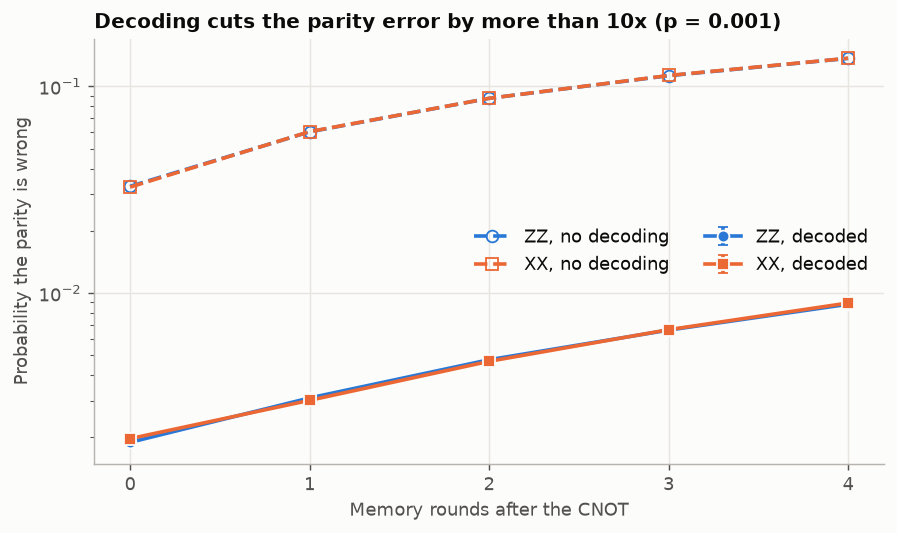

In [5]:
P_REF = 1e-3
fig, ax = plt.subplots(figsize=(7, 4.2))
for basis, colour, marker in [("ZZ", BLUE, "o"), ("XX", ORANGE, "s")]:
    d = results[(results.p == P_REF) & (results.basis == basis)]
    ax.plot(d.rounds, d.raw_error, ls="--", marker=marker, color=colour, mfc="none", label=f"{basis}, no decoding")
    ax.errorbar(d.rounds, d.decoded_error, yerr=d.decoded_se, marker=marker, color=colour, capsize=3,
                mec="#fcfcfb", mew=1, label=f"{basis}, decoded")
ax.set(yscale="log", xlabel="Memory rounds after the CNOT", ylabel="Probability the parity is wrong",
       xticks=ROUNDS, title=f"Decoding cuts the parity error by more than 10x (p = {P_REF:g})")
ax.legend(ncol=2, loc="center right")
fig.tight_layout()
plt.show()

## Bell-state fidelity

The lower bound $1 - e_{ZZ} - e_{XX}$ combines the two experiments, using decoded errors.

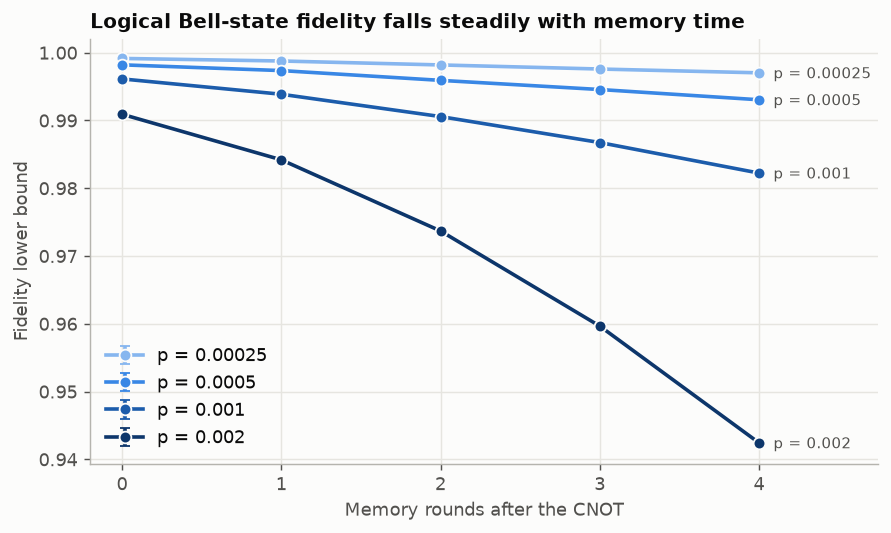

p,0.000250,0.000500,0.001000,0.002000
rounds,,,,
0,0.99916,0.99821,0.99613,0.99092
1,0.99878,0.99736,0.99387,0.98420
2,0.99820,0.99592,0.99058,0.97370
3,0.99759,0.99457,0.98675,0.95966
4,0.99703,0.99306,0.98224,0.94243


In [6]:
wide = results.pivot(index=["p", "rounds"], columns="basis", values=["decoded_error", "decoded_se", "raw_error"])
fidelity = pd.DataFrame({
    "infidelity_bound": wide["decoded_error"]["ZZ"] + wide["decoded_error"]["XX"],
    "se": np.hypot(wide["decoded_se"]["ZZ"], wide["decoded_se"]["XX"]),
    "raw_infidelity_bound": wide["raw_error"]["ZZ"] + wide["raw_error"]["XX"],
}).reset_index()
fidelity["fidelity_lower_bound"] = 1 - fidelity.infidelity_bound

fig, ax = plt.subplots(figsize=(7, 4.2))
for p, colour in zip(PHYSICAL_ERROR_RATES, RAMP):
    d = fidelity[fidelity.p == p]
    ax.errorbar(d.rounds, d.fidelity_lower_bound, yerr=d.se, marker="o", color=colour, capsize=3,
                mec="#fcfcfb", mew=1, label=f"p = {p:g}")
    ax.annotate(f"p = {p:g}", (d.rounds.iloc[-1], d.fidelity_lower_bound.iloc[-1]), xytext=(8, -3),
                textcoords="offset points", fontsize=8.5, color="#52514e")
ax.set(xlabel="Memory rounds after the CNOT", ylabel="Fidelity lower bound", xticks=ROUNDS,
       xlim=(-0.2, 4.75), title="Logical Bell-state fidelity falls steadily with memory time")
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

fidelity.pivot(index="rounds", columns="p", values="fidelity_lower_bound").style.format("{:.5f}")

## Scaling with the physical error rate

A fully fault-tolerant distance-3 circuit should give a decoded error scaling as $p^2$, a slope of 2 on this log-log plot. A slope near 1 means single faults are causing logical errors.

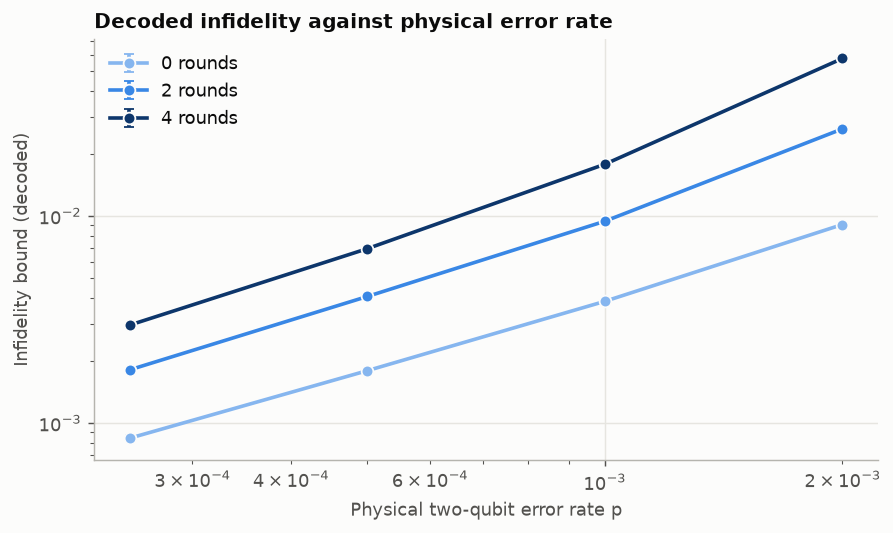

,log-log slope
rounds,
0,1.14
1,1.23
2,1.28
3,1.35
4,1.42


In [7]:
fig, ax = plt.subplots(figsize=(7, 4.2))
slopes = {}
for rounds, colour in zip([0, 2, 4], [RAMP[0], RAMP[1], RAMP[3]]):
    d = fidelity[fidelity.rounds == rounds]
    ax.errorbar(d.p, d.infidelity_bound, yerr=d.se, marker="o", color=colour, capsize=3,
                mec="#fcfcfb", mew=1, label=f"{rounds} rounds")
for rounds in ROUNDS:
    d = fidelity[fidelity.rounds == rounds]
    slopes[rounds] = np.polyfit(np.log(d.p), np.log(d.infidelity_bound), 1)[0]

ax.set(xscale="log", yscale="log", xlabel="Physical two-qubit error rate p",
       ylabel="Infidelity bound (decoded)", title="Decoded infidelity against physical error rate")
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

pd.Series(slopes, name="log-log slope").rename_axis("rounds").to_frame().style.format("{:.2f}")

## Logical error per round

If each round adds an independent chance $\epsilon$ of flipping a parity, then $1 - 2e(r) = A\,(1 - 2\epsilon)^r$. Fitting $\ln(1 - 2e)$ against $r$ gives $\epsilon$ for each basis. The fit is unweighted and spans only five points.

In [8]:
rows = []
for p in PHYSICAL_ERROR_RATES:
    row = {"p": p}
    for basis in ("ZZ", "XX"):
        d = results[(results.p == p) & (results.basis == basis)]
        slope = np.polyfit(d.rounds, np.log(1 - 2 * d.decoded_error), 1)[0]
        row[f"epsilon_{basis}"] = (1 - np.exp(slope)) / 2
    row["epsilon_ZZ / p"] = row["epsilon_ZZ"] / p
    row["epsilon_XX / p"] = row["epsilon_XX"] / p
    rows.append(row)
per_round = pd.DataFrame(rows)
per_round.style.format({"p": "{:.2e}", "epsilon_ZZ": "{:.2e}", "epsilon_XX": "{:.2e}",
                        "epsilon_ZZ / p": "{:.2f}", "epsilon_XX / p": "{:.2f}"}).hide(axis="index")

p,epsilon_ZZ,epsilon_XX,epsilon_ZZ / p,epsilon_XX / p
2.50e-04,2.65e-04,2.79e-04,1.06,1.12
5.00e-04,6.49e-04,6.66e-04,1.30,1.33
1.00e-03,1.75e-03,1.77e-03,1.75,1.77
2.00e-03,6.19e-03,6.29e-03,3.10,3.14


## Results

These figures come from the run above, with 1,000,000 shots per point and a fixed seed.

- **The logical Bell pair is stored with high fidelity at low noise.** At $p = 10^{-3}$ the fidelity lower bound is 0.9961 straight after the CNOT and 0.9822 after 4 memory rounds. At $p = 2.5\times10^{-4}$ it is 0.9992 and 0.9970.
- **Decoding helps a lot.** At $p = 10^{-3}$ it lowers the parity error by about 15 to 17 times, for example from $3.3\times10^{-2}$ to $1.9\times10^{-3}$ with no memory rounds.
- **$Z_LZ_L$ and $X_LX_L$ behave almost identically**, which fits the symmetric noise model and the identical X and Z checks.
- **Each round costs about $1.8\times10^{-3}$ per parity at $p = 10^{-3}$**, roughly 1.8 times the physical two-qubit error rate.

**Caveats**

- **The circuit does not show $p^2$ scaling.** The log-log slope is 1.14 with no memory rounds, well short of the 2 expected from a fault-tolerant distance-3 circuit. Single faults are causing logical errors, which is consistent with hook errors from bare ancillas and unverified state preparation. That cause has not been isolated here.
- **The decoder limits the deep, noisy points.** The steeper slopes at more rounds, and the rise in $\epsilon / p$ from 1.06 to 3.10 across the sweep, are probably partly a decoder effect. At $p = 2\times10^{-3}$ with 4 rounds, 3% of shots have a syndrome missing from the weight-2 table and get no correction, about the same size as the 2.9% decoded error. Treat those points as an upper limit on what a better decoder would achieve.
- **Fidelity is a lower bound.** It comes from the $Z_LZ_L$ and $X_LX_L$ parities only.
- **The number of rounds is capped at 4** by the decoder's 62-detector key.